# Task 3 — Supervised Classification, Model Comparison & Hyperparameter Tuning

This notebook trains four classification architectures, tunes them with GridSearchCV and stratified 5-fold cross-validation, evaluates them, compares ROC-AUC curves, selects a validation-based champion, and serializes it.

**Dataset:** Breast Cancer Wisconsin Diagnostic dataset bundled with scikit-learn: 569 rows and 30 numerical predictors. It is used here because it is large enough for cross-validation and is self-contained.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report, roc_curve
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
RANDOM_STATE=42

## 1. Load the dataset

In [2]:
data=load_breast_cancer(as_frame=True)
X=data.data.copy()
y=1-data.target.copy()  # malignant=1, benign=0
print("Dataset shape:",X.shape)
print("Class counts:")
print(y.value_counts().rename(index={0:"benign",1:"malignant"}))
print("\nMissing values:",int(X.isna().sum().sum()))

Dataset shape: (569, 30)
Class counts:
target
benign       357
malignant    212
Name: count, dtype: int64

Missing values: 0


## 2. Train/test split before model fitting

In [3]:
X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.20,random_state=RANDOM_STATE,stratify=y)
print("Training rows:",len(X_train))
print("Test rows:",len(X_test))

Training rows: 455
Test rows: 114


## 3. Stratified K-fold cross-validation

In [4]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=RANDOM_STATE)
print(cv)

StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


## 4. Define four distinct model architectures

In [5]:
from xgboost import XGBClassifier
models={
"Logistic Regression":Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",StandardScaler()),("model",LogisticRegression(max_iter=3000,random_state=RANDOM_STATE))]),
"Random Forest":Pipeline([("imputer",SimpleImputer(strategy="median")),("model",RandomForestClassifier(random_state=RANDOM_STATE,n_jobs=-1))]),
"Gradient Boosting":Pipeline([("imputer",SimpleImputer(strategy="median")),("model",GradientBoostingClassifier(random_state=RANDOM_STATE))]),
"XGBoost":Pipeline([("imputer",SimpleImputer(strategy="median")),("model",XGBClassifier(objective="binary:logistic",eval_metric="logloss",random_state=RANDOM_STATE,n_jobs=-1,tree_method="hist"))])
}
print("Models:",list(models.keys()))

Models: ['Logistic Regression', 'Random Forest', 'Gradient Boosting', 'XGBoost']


## 5. Hyperparameter grids

In [6]:
param_grids={
"Logistic Regression":{"model__C":[0.1,1.0,10.0],"model__solver":["liblinear","lbfgs"]},
"Random Forest":{"model__n_estimators":[100,250],"model__max_depth":[None,5,10],"model__min_samples_split":[2,5]},
"Gradient Boosting":{"model__n_estimators":[50,100],"model__learning_rate":[0.05,0.1],"model__max_depth":[2,3]},
"XGBoost":{"model__n_estimators":[100,200],"model__max_depth":[2,4],"model__learning_rate":[0.05,0.1],"model__subsample":[0.8,1.0]}
}
print("Hyperparameter grids defined for",len(param_grids),"models.")

Hyperparameter grids defined for 4 models.


## 6. GridSearchCV with stratified cross-validation

In [7]:
searches={}
cv_rows=[]
for name,pipeline in models.items():
    print(f"\nTuning {name}...")
    search=GridSearchCV(pipeline,param_grids[name],scoring="roc_auc",cv=cv,n_jobs=-1,refit=True)
    search.fit(X_train,y_train)
    searches[name]=search
    cv_rows.append({"model":name,"cv_roc_auc":search.best_score_,"best_params":search.best_params_})
    print("Best CV ROC-AUC:",round(search.best_score_,4))
    print("Best parameters:",search.best_params_)
cv_results=pd.DataFrame(cv_rows).sort_values("cv_roc_auc",ascending=False).reset_index(drop=True)
cv_results


Tuning Logistic Regression...
Best CV ROC-AUC: 0.9959
Best parameters: {'model__C': 1.0, 'model__solver': 'liblinear'}

Tuning Random Forest...
Best CV ROC-AUC: 0.989
Best parameters: {'model__max_depth': 10, 'model__min_samples_split': 2, 'model__n_estimators': 100}

Tuning Gradient Boosting...
Best CV ROC-AUC: 0.9909
Best parameters: {'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 100}

Tuning XGBoost...
Best CV ROC-AUC: 0.9945
Best parameters: {'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 200, 'model__subsample': 0.8}


,model,cv_roc_auc,best_params
0,Logistic Regression,0.995872,"{'model__C': 1.0, 'model__solver': 'liblinear'}"
1,XGBoost,0.994530,"{'model__learning_rate': 0.1, 'model__max_dept..."
2,Gradient Boosting,0.990918,"{'model__learning_rate': 0.1, 'model__max_dept..."
3,Random Forest,0.988958,"{'model__max_depth': 10, 'model__min_samples_s..."


## 7. Select the champion using validation ROC-AUC

In [8]:
champion_name=cv_results.loc[0,"model"]
champion_search=searches[champion_name]
champion_model=champion_search.best_estimator_
print("Champion model selected from mean CV ROC-AUC:",champion_name)
print("Best mean CV ROC-AUC:",round(champion_search.best_score_,4))
print("Best parameters:",champion_search.best_params_)

Champion model selected from mean CV ROC-AUC: Logistic Regression
Best mean CV ROC-AUC: 0.9959
Best parameters: {'model__C': 1.0, 'model__solver': 'liblinear'}


## 8. Evaluate all tuned models on the untouched test set

In [9]:
evaluation_rows=[]
for name,search in searches.items():
    estimator=search.best_estimator_
    y_pred=estimator.predict(X_test)
    y_prob=estimator.predict_proba(X_test)[:,1]
    evaluation_rows.append({
        "model":name,
        "test_accuracy":accuracy_score(y_test,y_pred),
        "precision":precision_score(y_test,y_pred,zero_division=0),
        "recall":recall_score(y_test,y_pred,zero_division=0),
        "f1_score":f1_score(y_test,y_pred,zero_division=0),
        "test_roc_auc":roc_auc_score(y_test,y_prob)})
evaluation_table=pd.DataFrame(evaluation_rows).sort_values("test_roc_auc",ascending=False).reset_index(drop=True)
evaluation_table.round(4)

,model,test_accuracy,precision,recall,f1_score,test_roc_auc
0,Logistic Regression,0.9737,0.9756,0.9524,0.9639,0.9960
1,Random Forest,0.9737,1.0000,0.9286,0.9630,0.9929
2,Gradient Boosting,0.9649,1.0000,0.9048,0.9500,0.9927
3,XGBoost,0.9737,1.0000,0.9286,0.9630,0.9917


## 9. Champion confusion matrix and classification report

In [10]:
champion_pred=champion_model.predict(X_test)
champion_prob=champion_model.predict_proba(X_test)[:,1]
print("Champion:",champion_name)
print("\nConfusion matrix:")
print(confusion_matrix(y_test,champion_pred))
print("\nClassification report:")
print(classification_report(y_test,champion_pred,target_names=["benign","malignant"],zero_division=0))

Champion: Logistic Regression

Confusion matrix:
[[71  1]
 [ 2 40]]

Classification report:
              precision    recall  f1-score   support

      benign       0.97      0.99      0.98        72
   malignant       0.98      0.95      0.96        42

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



## 10. ROC-AUC curves for all tuned models

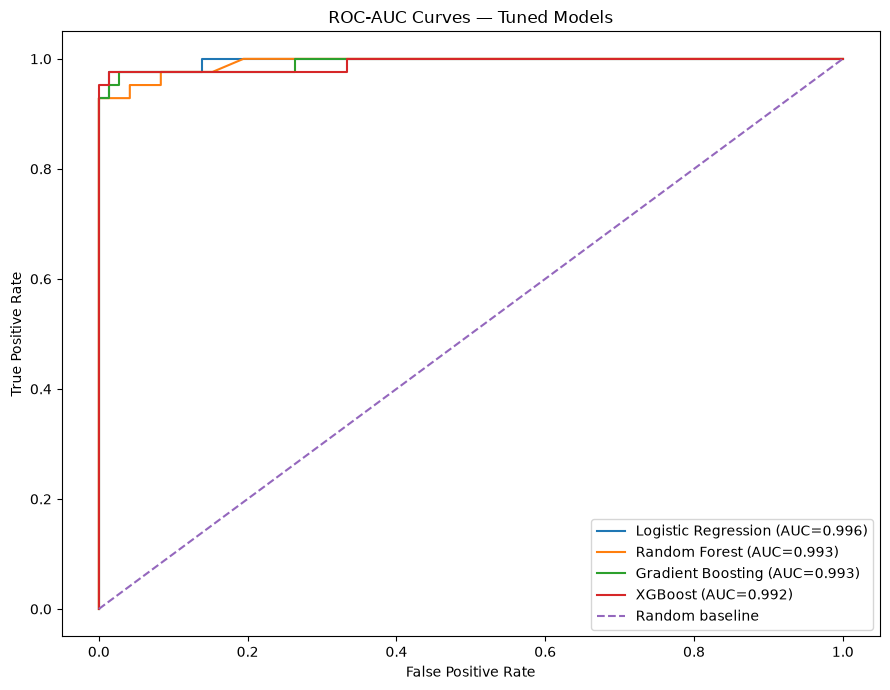

In [11]:
plt.figure(figsize=(9,7))
for name,search in searches.items():
    y_prob=search.best_estimator_.predict_proba(X_test)[:,1]
    fpr,tpr,_=roc_curve(y_test,y_prob)
    auc=roc_auc_score(y_test,y_prob)
    plt.plot(fpr,tpr,label=f"{name} (AUC={auc:.3f})")
plt.plot([0,1],[0,1],linestyle="--",label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-AUC Curves — Tuned Models")
plt.legend()
plt.tight_layout()
plt.show()

## 11. Serialize the champion model

In [17]:
from pathlib import Path
import joblib
model_path=Path("../models/champion_model.joblib")
joblib.dump(champion_model,model_path)
print("Saved:",model_path.resolve())
print("Exists:",model_path.exists())

Saved: E:\Classification-Modeling-Tuning\models\champion_model.joblib
Exists: True


## 12. Reload serialized model and verify

In [18]:
loaded_champion=joblib.load(model_path)
reloaded_prob=loaded_champion.predict_proba(X_test)[:,1]
print("Reloaded model:",type(loaded_champion.named_steps["model"]).__name__)
print("Reloaded test ROC-AUC:",round(roc_auc_score(y_test,reloaded_prob),4))

Reloaded model: LogisticRegression
Reloaded test ROC-AUC: 0.996


## 13. Leakage and evaluation checklist

- Train/test split occurs before model fitting.
- Preprocessing is inside each model pipeline.
- Hyperparameter tuning uses only the training set with StratifiedKFold.
- The test set is held out until final evaluation.
- Champion selection uses mean cross-validation ROC-AUC, not test performance.
- Precision, recall, F1-score, ROC-AUC, and confusion matrix are reported.
- ROC-AUC curves compare all tuned architectures.
- The champion model is serialized to `models/champion_model.joblib`.

**Interpretation note:** this is an educational modeling exercise, not evidence for clinical deployment.

## 14. Conclusion

This notebook demonstrates supervised classification, model comparison, hyperparameter optimization, leakage-aware evaluation, ROC-AUC visualization, and model serialization in a reusable scikit-learn workflow.